# JS11 Praktikum 2 PBL - SVM RBF

Notebook ini merupakan implementasi PBL menggunakan dataset *Sleep Health and Lifestyle*.

## 1. Tujuan

Menggunakan kernel RBF pada SVM untuk memodelkan hubungan nonlinear.

## 2. Dataset dan Alur Praktikum

Dataset disimpan pada `Dataset/Sleep_health_and_lifestyle_dataset.csv`. Alur: **load -> cleaning -> feature engineering -> pemodelan -> evaluasi -> visualisasi**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.style.use("seaborn-v0_8-whitegrid")

csv_path = Path("../Dataset/Sleep_health_and_lifestyle_dataset.csv")
df = pd.read_csv(csv_path)
print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 3. Eksplorasi dan Pembersihan Data

In [2]:
print("Informasi dataset:")
df.info()

print("\nNilai kosong:")
print(df.isna().sum())
print("\nDuplikasi:", df.duplicated().sum())

df = df.copy()
df["Sleep Disorder"] = df["Sleep Disorder"].fillna("None")

bp = df["Blood Pressure"].str.split("/", expand=True).astype(float)
df["Systolic BP"] = bp[0]
df["Diastolic BP"] = bp[1]
print("\nDistribusi Sleep Disorder:")
print(df["Sleep Disorder"].value_counts())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 38.1 KB

Nilai kosong:
Per

### Cek kualitas data dan ringkasan statistik

,count,mean,std,min,25%,50%,75%,max
Person ID,374.0,187.500000,108.108742,1.0,94.25,187.5,280.75,374.0
Age,374.0,42.184492,8.673133,27.0,35.25,43.0,50.00,59.0
Sleep Duration,374.0,7.132086,0.795657,5.8,6.40,7.2,7.80,8.5
Quality of Sleep,374.0,7.312834,1.196956,4.0,6.00,7.0,8.00,9.0
Physical Activity Level,374.0,59.171123,20.830804,30.0,45.00,60.0,75.00,90.0
Stress Level,374.0,5.385027,1.774526,3.0,4.00,5.0,7.00,8.0
Heart Rate,374.0,70.165775,4.135676,65.0,68.00,70.0,72.00,86.0
Daily Steps,374.0,6816.844920,1617.915679,3000.0,5600.00,7000.0,8000.00,10000.0
Systolic BP,374.0,128.553476,7.748118,115.0,125.00,130.0,135.00,142.0
Diastolic BP,374.0,84.649733,6.161611,75.0,80.00,85.0,90.00,95.0


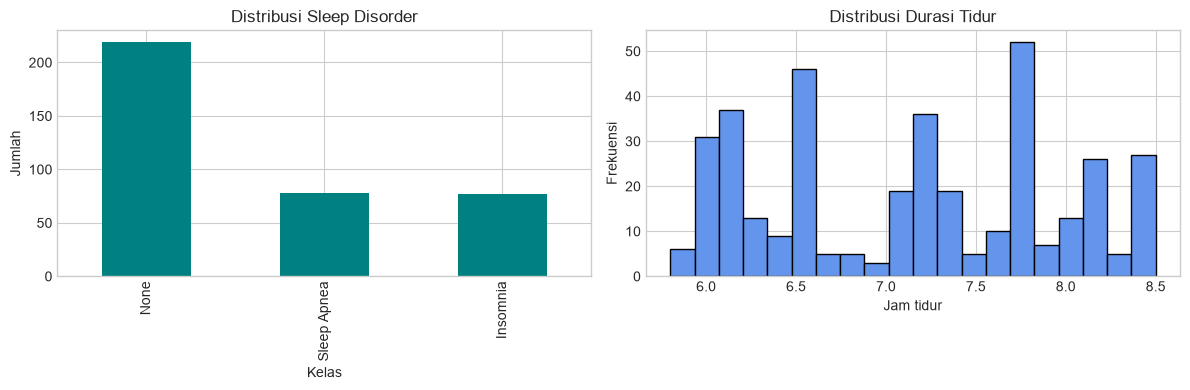

In [3]:
display(df.describe(include="number").T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Sleep Disorder"].value_counts().plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Distribusi Sleep Disorder")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah")

df["Sleep Duration"].hist(bins=20, ax=axes[1], color="cornflowerblue", edgecolor="black")
axes[1].set_title("Distribusi Durasi Tidur")
axes[1].set_xlabel("Jam tidur")
axes[1].set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

## 4. Feature Engineering dan Persiapan Fitur

In [4]:
drop_columns = ["Person ID", "Blood Pressure", "Sleep Disorder"]
X = df.drop(columns=drop_columns)
y = df["Sleep Disorder"]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

print("Fitur numerik:", numeric_features)
print("Fitur kategorik:", categorical_features)
print("Ukuran matriks fitur:", X.shape)

Fitur numerik: ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP']
Fitur kategorik: ['Gender', 'Occupation', 'BMI Category']
Ukuran matriks fitur: (374, 12)


## 5. Pembagian Data dan Pelatihan Model

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Proporsi train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Proporsi test :", y_test.value_counts(normalize=True).round(3).to_dict())

Train: (299, 12) Test: (75, 12)
Proporsi train: {'None': 0.585, 'Sleep Apnea': 0.207, 'Insomnia': 0.207}
Proporsi test : {'None': 0.587, 'Sleep Apnea': 0.213, 'Insomnia': 0.2}


## 6. Pelatihan SVM

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale")),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Kernel:", "rbf")


Kernel: rbf


## 6. Evaluasi dan Visualisasi

              precision    recall  f1-score   support

    Insomnia       1.00      0.87      0.93        15
        None       1.00      1.00      1.00        44
 Sleep Apnea       0.89      1.00      0.94        16

    accuracy                           0.97        75
   macro avg       0.96      0.96      0.96        75
weighted avg       0.98      0.97      0.97        75



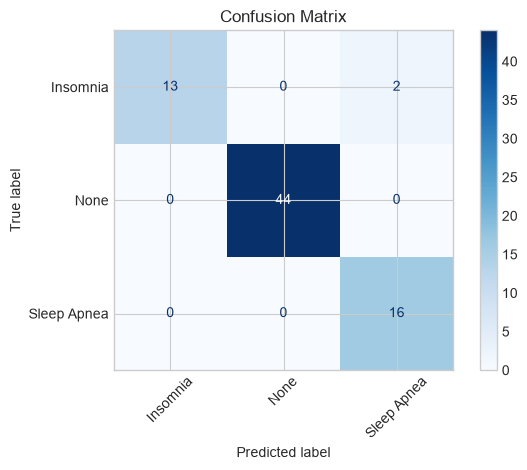

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", xticks_rotation=45
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Kesimpulan

Catat parameter model terbaik, hasil evaluasi, serta hubungan temuan dengan kasus Sleep Wise.